<a href="https://colab.research.google.com/github/jar7is/Smart-City-Traffic-Flow-Simulator/blob/main/Smart_City_Traffic_Flow_Simulator_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Smart City Traffic Flow Simulator — EDA Project

**Goal:** Simulate 30 days of hourly vehicle counts across 10 junctions, explore rush-hour patterns, identify potential traffic bottlenecks, and compare loop-based versus vectorized NumPy calculations.

> **Data note:** This project uses synthetic/simulated traffic counts generated with a Poisson model. It is not real traffic sensor data, and conclusions apply only to this simulation.

## Questions this analysis will answer
1. Which hours have the highest average traffic?
2. Which junctions carry the highest average and peak traffic?
3. Are morning and evening rush-hour patterns visible?
4. Which junction-hour combinations are potential bottlenecks?
5. How much faster is a vectorized NumPy calculation than a Python loop?

## Notebook workflow
1. Import libraries and set a reproducible random seed.
2. Create hourly traffic counts.
3. Convert the simulation into a tidy pandas DataFrame.
4. Perform summary statistics and EDA.
5. Visualize patterns with line charts, bar charts, and a heatmap.
6. Benchmark loop-based versus vectorized aggregation.
7. Export the dataset and summary tables for GitHub.

In [1]:
# 1. Imports and reproducibility
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

NUM_DAYS = 30
NUM_JUNCTIONS = 10
HOURS_PER_DAY = 24

print("NumPy version:", np.__version__)
print("pandas version:", pd.__version__)
print(f"Simulation size: {NUM_DAYS} days × {NUM_JUNCTIONS} junctions × {HOURS_PER_DAY} hours = {NUM_DAYS * NUM_JUNCTIONS * HOURS_PER_DAY:,} records")

NumPy version: 2.1.3
pandas version: 2.2.3
Simulation size: 30 days × 10 junctions × 24 hours = 7,200 records


## 2. Simulate traffic counts

We model expected traffic using a daily hourly pattern: traffic is higher during the morning commute and evening commute, and lower overnight. Each junction receives a slightly different traffic multiplier.

A Poisson distribution is a reasonable introductory model for count data. It generates non-negative integer vehicle counts around an expected rate (`lambda`). This is a simplified simulation, not a validated traffic forecasting model.

In [2]:
# 2. Create the expected hourly traffic pattern
hours = np.arange(HOURS_PER_DAY)

# Baseline expected vehicles per hour
hourly_pattern = np.full(HOURS_PER_DAY, 18.0)

# Morning rush peak around 8 AM and evening peak around 6 PM
morning_peak = 75 * np.exp(-0.5 * ((hours - 8) / 1.7) ** 2)
evening_peak = 95 * np.exp(-0.5 * ((hours - 18) / 2.0) ** 2)
midday_activity = 20 * np.exp(-0.5 * ((hours - 13) / 3.0) ** 2)

hourly_pattern = hourly_pattern + morning_peak + evening_peak + midday_activity

# Different junctions have different traffic volumes
junction_multipliers = np.array([0.75, 0.90, 1.05, 1.20, 0.85, 1.35, 0.95, 1.10, 0.65, 1.25])

# Slight day-to-day variation; weekends are assumed to be a little quieter
day_multipliers = np.ones(NUM_DAYS)
day_multipliers[np.arange(NUM_DAYS) % 7 >= 5] = 0.82
day_multipliers *= rng.normal(loc=1.0, scale=0.06, size=NUM_DAYS)
day_multipliers = np.clip(day_multipliers, 0.75, 1.20)

# Lambda shape: (days, junctions, hours)
lam = (
    day_multipliers[:, None, None]
    * junction_multipliers[None, :, None]
    * hourly_pattern[None, None, :]
)

traffic = rng.poisson(lam=lam)

print("Traffic array shape:", traffic.shape)
print("Minimum count:", traffic.min())
print("Maximum count:", traffic.max())
print("Mean vehicles per junction-hour:", round(float(traffic.mean()), 2))

Traffic array shape: (30, 10, 24)
Minimum count: 4
Maximum count: 183
Mean vehicles per junction-hour: 54.93


## 3. Convert to a tidy dataset

Each row represents one day, one junction, and one hour. This makes filtering, grouping, charting, and exporting straightforward.

In [3]:
# Build one row per day × junction × hour
day_idx, junction_idx, hour_idx = np.indices(traffic.shape)

df = pd.DataFrame({
    "day": day_idx.ravel() + 1,
    "junction": [f"Junction {j+1:02d}" for j in junction_idx.ravel()],
    "hour": hour_idx.ravel(),
    "vehicles": traffic.ravel()
})

df["period"] = np.select(
    [
        df["hour"].between(6, 10),
        df["hour"].between(16, 20)
    ],
    ["Morning rush", "Evening rush"],
    default="Off-peak"
)

df.head(10)

,day,junction,hour,vehicles,period
0,1,Junction 01,0,12,Off-peak
1,1,Junction 01,1,13,Off-peak
2,1,Junction 01,2,9,Off-peak
3,1,Junction 01,3,11,Off-peak
4,1,Junction 01,4,17,Off-peak
5,1,Junction 01,5,29,Off-peak
6,1,Junction 01,6,41,Morning rush
7,1,Junction 01,7,68,Morning rush
8,1,Junction 01,8,66,Morning rush
9,1,Junction 01,9,76,Morning rush


## 4. Data quality checks and descriptive statistics

Even synthetic data should be checked before analysis. We verify row count, missing values, duplicates, and basic distribution statistics.

In [4]:
expected_rows = NUM_DAYS * NUM_JUNCTIONS * HOURS_PER_DAY

quality_report = pd.Series({
    "Rows": len(df),
    "Expected rows": expected_rows,
    "Missing cells": int(df.isna().sum().sum()),
    "Duplicate day-junction-hour keys": int(df.duplicated(["day", "junction", "hour"]).sum()),
    "Negative vehicle counts": int((df["vehicles"] < 0).sum())
})

display(quality_report.to_frame("value"))
display(df["vehicles"].describe().to_frame("vehicles"))

,value
Rows,7200
Expected rows,7200
Missing cells,0
Duplicate day-junction-hour keys,0
Negative vehicle counts,0


,vehicles
count,7200.000000
mean,54.930139
std,34.420719
min,4.000000
25%,26.000000
50%,48.000000
75%,77.000000
max,183.000000


## 5. Find peak hours and busiest junctions

We aggregate traffic by hour and by junction. `idxmax()` returns the label where a maximum occurs, which helps identify the peak hour and busiest junction in the simulated data.

In [5]:
hourly_summary = (
    df.groupby("hour")["vehicles"]
      .agg(["mean", "median", "max", "sum"])
      .rename(columns={"mean": "avg_vehicles", "median": "median_vehicles",
                       "max": "peak_vehicles", "sum": "total_vehicles"})
)

junction_summary = (
    df.groupby("junction")["vehicles"]
      .agg(["mean", "max", "sum"])
      .rename(columns={"mean": "avg_vehicles", "max": "peak_hour_vehicles",
                       "sum": "total_vehicles"})
      .sort_values("avg_vehicles", ascending=False)
)

peak_hour = int(hourly_summary["avg_vehicles"].idxmax())
busiest_junction = junction_summary["avg_vehicles"].idxmax()

print(f"Highest average traffic hour: {peak_hour:02d}:00")
print(f"Busiest junction by average hourly count: {busiest_junction}")
display(hourly_summary.round(2))
display(junction_summary.round(2))

Highest average traffic hour: 18:00
Busiest junction by average hourly count: Junction 06


,avg_vehicles,median_vehicles,peak_vehicles,total_vehicles
hour,,,,
0,17.25,17.0,34,5174
1,17.48,17.0,36,5244
2,17.60,18.0,32,5280
3,18.11,17.5,37,5433
4,21.88,21.0,43,6564
5,32.99,32.0,69,9896
6,54.49,54.0,95,16346
7,79.53,80.0,135,23859
8,93.51,94.0,156,28052


,avg_vehicles,peak_hour_vehicles,total_vehicles
junction,,,
Junction 06,74.03,183,53305
Junction 10,68.23,175,49129
Junction 04,66.03,171,47543
Junction 08,60.14,152,43304
Junction 03,57.01,155,41045
Junction 07,52.21,128,37592
Junction 02,49.03,136,35302
Junction 05,46.29,115,33332
Junction 01,40.98,106,29502


## 6. Visualize the traffic patterns

The plots show the average hourly traffic profile, average traffic by junction, and the hour-by-junction heatmap. These are descriptive patterns in the simulated data.

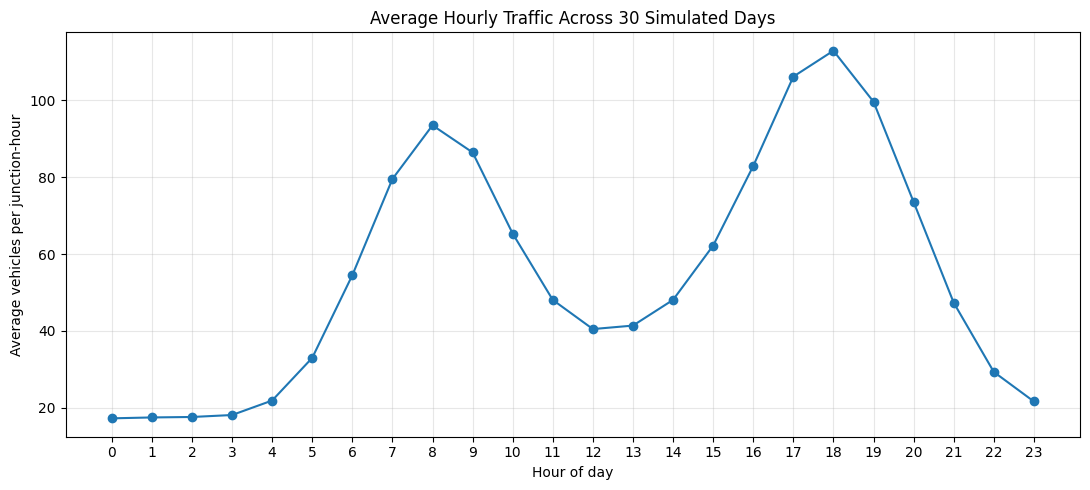

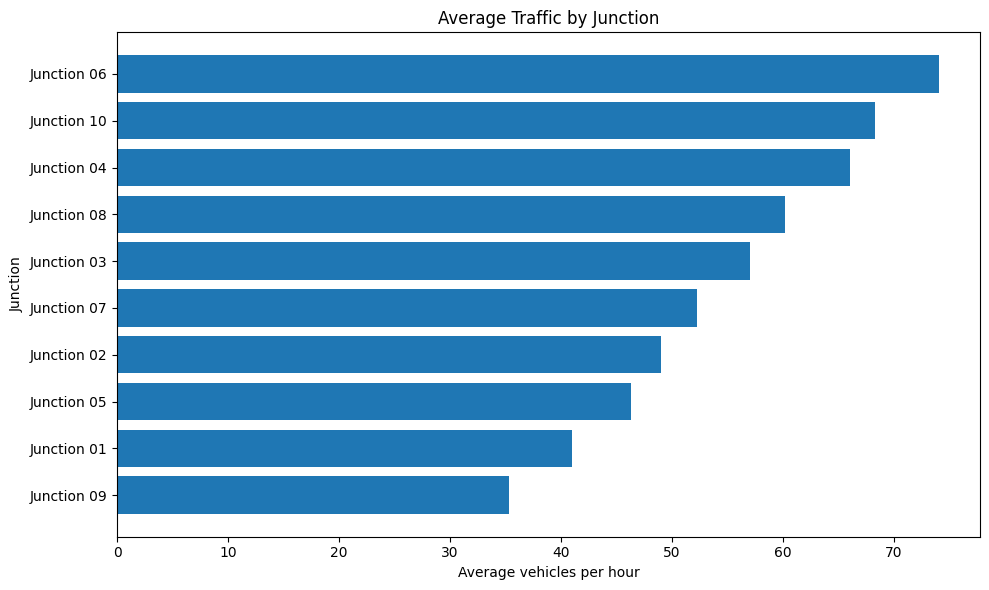

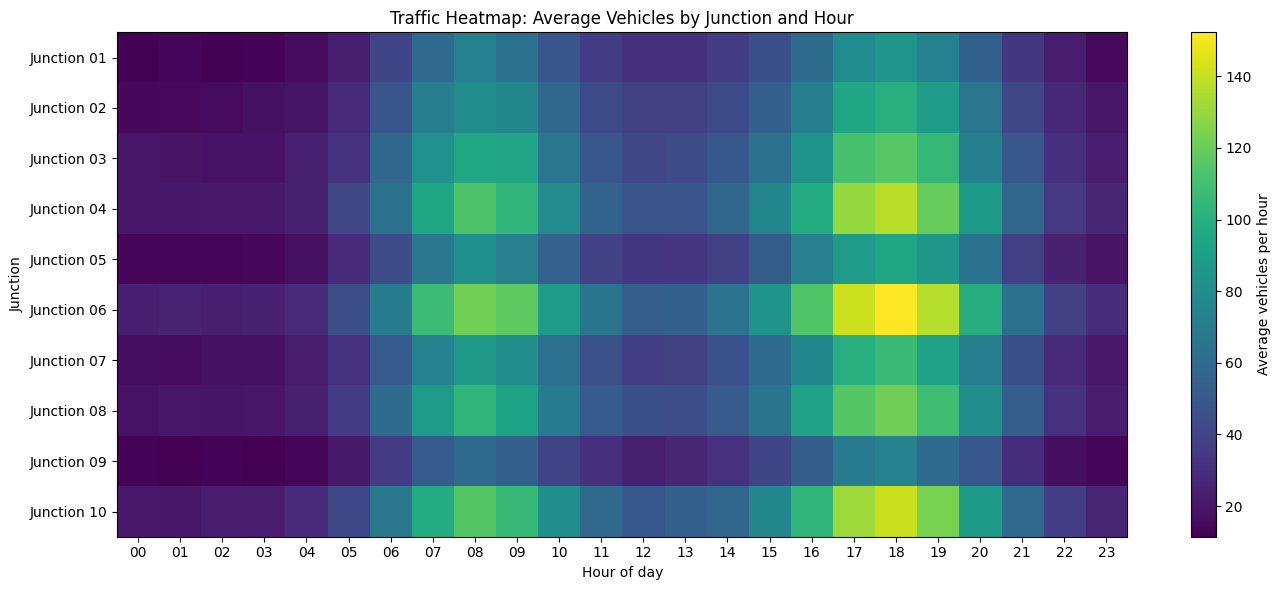

In [6]:
# Chart 1: average traffic by hour
plt.figure(figsize=(11, 5))
plt.plot(hourly_summary.index, hourly_summary["avg_vehicles"], marker="o")
plt.xticks(range(0, 24))
plt.xlabel("Hour of day")
plt.ylabel("Average vehicles per junction-hour")
plt.title("Average Hourly Traffic Across 30 Simulated Days")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Chart 2: average traffic by junction
junction_plot = junction_summary.sort_values("avg_vehicles")
plt.figure(figsize=(10, 6))
plt.barh(junction_plot.index, junction_plot["avg_vehicles"])
plt.xlabel("Average vehicles per hour")
plt.ylabel("Junction")
plt.title("Average Traffic by Junction")
plt.tight_layout()
plt.show()

# Chart 3: heatmap of average traffic by junction and hour
heatmap_data = df.pivot_table(
    index="junction", columns="hour", values="vehicles", aggfunc="mean"
)
plt.figure(figsize=(14, 6))
plt.imshow(heatmap_data, aspect="auto", interpolation="nearest")
plt.colorbar(label="Average vehicles per hour")
plt.xticks(range(24), [f"{h:02d}" for h in range(24)])
plt.yticks(range(len(heatmap_data.index)), heatmap_data.index)
plt.xlabel("Hour of day")
plt.ylabel("Junction")
plt.title("Traffic Heatmap: Average Vehicles by Junction and Hour")
plt.tight_layout()
plt.show()

## 7. Identify potential bottleneck windows

For this project, a potential bottleneck is defined as a junction-hour whose average count is in the top 10% of all junction-hour averages. This is a transparent, relative threshold for the simulation—not a real-world congestion standard. Real bottleneck detection would also need road capacity, speed, queue length, and signal timing.

In [7]:
junction_hour = df.groupby(["junction", "hour"])["vehicles"].mean().rename("avg_vehicles").reset_index()
threshold = junction_hour["avg_vehicles"].quantile(0.90)
bottlenecks = junction_hour[junction_hour["avg_vehicles"] >= threshold].sort_values(
    "avg_vehicles", ascending=False
)

print(f"Top-10% threshold for average junction-hour traffic: {threshold:.2f} vehicles/hour")
display(bottlenecks.head(15).round(2))

# Rush-hour vs off-peak comparison
period_summary = df.groupby("period")["vehicles"].agg(["mean", "median", "sum", "count"])
display(period_summary.round(2))

Top-10% threshold for average junction-hour traffic: 104.17 vehicles/hour


,junction,hour,avg_vehicles
138,Junction 06,18,152.30
137,Junction 06,17,141.53
234,Junction 10,18,141.20
90,Junction 04,18,137.40
139,Junction 06,19,136.73
233,Junction 10,17,131.47
89,Junction 04,17,130.10
235,Junction 10,19,124.20
128,Junction 06,8,122.40
186,Junction 08,18,121.70


,mean,median,sum,count
period,,,,
Evening rush,95.04,93.0,142561,1500
Morning rush,75.86,73.0,113790,1500
Off-peak,33.13,29.0,139146,4200


## 8. Benchmark loops vs vectorized NumPy

We compare two ways to calculate total traffic for each hour across all days and junctions:
- **Loop approach:** Python loops visit every day and junction.
- **Vectorized approach:** NumPy sums across axes in compiled array operations.

Both methods calculate the same hourly totals. Timing can vary depending on the computer, runtime load, and array size, so treat the result as a benchmark for this run—not a universal speed claim.

In [8]:
def totals_with_loops(arr):
    days, junctions, hours_count = arr.shape
    totals = np.zeros(hours_count, dtype=np.int64)
    for d in range(days):
        for j in range(junctions):
            for h in range(hours_count):
                totals[h] += arr[d, j, h]
    return totals

def totals_vectorized(arr):
    return arr.sum(axis=(0, 1))

# Warm-up and correctness check
loop_result = totals_with_loops(traffic)
vector_result = totals_vectorized(traffic)
assert np.array_equal(loop_result, vector_result), "Results do not match!"

start = time.perf_counter()
_ = totals_with_loops(traffic)
loop_seconds = time.perf_counter() - start

start = time.perf_counter()
_ = totals_vectorized(traffic)
vector_seconds = time.perf_counter() - start

speedup = loop_seconds / vector_seconds if vector_seconds > 0 else float("inf")

benchmark = pd.DataFrame({
    "method": ["Python loops", "Vectorized NumPy"],
    "execution_time_seconds": [loop_seconds, vector_seconds]
})

display(benchmark)
print(f"Measured speedup (loop time / vectorized time): {speedup:.2f}×")

,method,execution_time_seconds
0,Python loops,0.006282
1,Vectorized NumPy,0.000149


Measured speedup (loop time / vectorized time): 42.23×


## 9. Key findings — generated from this run

Use these outputs in your GitHub README only after running the notebook. Because the data is random (with a fixed seed for reproducibility), the same setup should produce repeatable results in the same software environment.

In [9]:
top_junction = junction_summary.index[0]
top_junction_avg = junction_summary.iloc[0]["avg_vehicles"]
overall_avg = df["vehicles"].mean()
morning_avg = df.loc[df["period"] == "Morning rush", "vehicles"].mean()
evening_avg = df.loc[df["period"] == "Evening rush", "vehicles"].mean()
offpeak_avg = df.loc[df["period"] == "Off-peak", "vehicles"].mean()

findings = [
    f"The highest average traffic hour was {peak_hour:02d}:00.",
    f"{top_junction} had the highest average hourly count ({top_junction_avg:.2f} vehicles/hour).",
    f"Overall average traffic was {overall_avg:.2f} vehicles per junction-hour.",
    f"Morning rush average: {morning_avg:.2f}; evening rush average: {evening_avg:.2f}; off-peak average: {offpeak_avg:.2f}.",
    f"{len(bottlenecks)} junction-hour combinations met the chosen top-10% bottleneck threshold.",
    f"Vectorized aggregation was {speedup:.2f}× the loop runtime in this run."
]

for i, finding in enumerate(findings, 1):
    print(f"{i}. {finding}")

1. The highest average traffic hour was 18:00.
2. Junction 06 had the highest average hourly count (74.03 vehicles/hour).
3. Overall average traffic was 54.93 vehicles per junction-hour.
4. Morning rush average: 75.86; evening rush average: 95.04; off-peak average: 33.13.
5. 24 junction-hour combinations met the chosen top-10% bottleneck threshold.
6. Vectorized aggregation was 42.23× the loop runtime in this run.


## 10. Export files for GitHub

This cell saves the simulated dataset and key summary tables. In Google Colab, the files appear in the Files panel and can be downloaded or committed to your GitHub repository. The complete notebook itself is also the main deliverable.

In [10]:
df.to_csv("traffic_simulation.csv", index=False)
hourly_summary.to_csv("hourly_summary.csv")
junction_summary.to_csv("junction_summary.csv")
bottlenecks.to_csv("potential_bottlenecks.csv", index=False)

print("Exported:")
print("- traffic_simulation.csv")
print("- hourly_summary.csv")
print("- junction_summary.csv")
print("- potential_bottlenecks.csv")

Exported:
- traffic_simulation.csv
- hourly_summary.csv
- junction_summary.csv
- potential_bottlenecks.csv


## Conclusion and limitations

This notebook demonstrates synthetic data generation, data quality checks, aggregation, visualization, threshold-based hotspot identification, and a simple performance benchmark.

**Limitations**
- Counts are simulated, not collected from real traffic sensors.
- Poisson assumptions and manually chosen rush-hour curves simplify real traffic behavior.
- Vehicle counts alone do not prove congestion; road capacity, travel speed, queue lengths, incidents, and signal timing would be needed.
- The loop-vs-vectorized benchmark is small and may vary between runs and machines.

**Possible next steps**
- Replace synthetic counts with an open city traffic dataset.
- Add weather, holidays, incidents, and road-capacity data.
- Compare weekdays and weekends more carefully.
- Build a dashboard with Plotly or Streamlit.